# DailyTalk (`eustlb/dailytalk`) — EDA + Preprocessing complets

**Pipeline :**
0. Config & chargement
1. Inspection du schéma (détection automatique des colonnes)
2. Statistiques audio (1 passe, sans garder l'audio en RAM)
3. EDA : métadonnées, texte, audio, structure des dialogues
4. Preprocessing texte + filtrage des outliers + dédoublonnage
5. Preprocessing audio (mono, 16 kHz, trim silence, normalisation)
6. Features de dialogue, encodage des labels, poids de classes
7. Split train/val/test **par conversation** (anti-fuite)
8. Sauvegarde (CSV + wav + rapport JSON)

> Si le dataset est protégé : `huggingface-cli login` (ou `from huggingface_hub import notebook_login; notebook_login()`).

## 0. Imports & configuration

## 1. Chargement & inspection du schéma

In [1]:
%pip install -q datasets soundfile librosa pandas numpy matplotlib scikit-learn tqdm pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import io
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from datasets import Audio, concatenate_datasets, load_dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

DATASET = "eustlb/dailytalk"

# Détection du dossier racine SpeechToText.
# Fonctionne si le notebook est lancé depuis :
# - ml/
# - ml/SpeechToText/
# - ml/SpeechToText/notebooks/
cwd = Path.cwd().resolve()
PROJECT_DIR = next((p for p in [cwd, *cwd.parents] if p.name.lower() == "speechtotext"), None)
if PROJECT_DIR is None and (cwd / "SpeechToText").is_dir():
    PROJECT_DIR = cwd / "SpeechToText"
if PROJECT_DIR is None and cwd.name.lower() == "notebooks" and cwd.parent.name.lower() == "speechtotext":
    PROJECT_DIR = cwd.parent
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Impossible de localiser le dossier SpeechToText. "
        "Placez ce notebook dans ml/SpeechToText/notebooks/."
    )

# Organisation des sorties dans SpeechToText/data/
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = PROCESSED_DIR / "figures"
AUDIO_DIR = PROCESSED_DIR / "audio_16k"

for d in (RAW_DIR, PROCESSED_DIR, FIG_DIR, AUDIO_DIR):
    d.mkdir(parents=True, exist_ok=True)

TARGET_SR = 16_000          # fréquence cible (ASR/Whisper/wav2vec = 16 kHz)
MIN_DUR, MAX_DUR = 0.3, 30  # bornes de durée (s) pour le filtrage
TRIM_TOP_DB = 35            # seuil de silence pour librosa.effects.trim
PEAK_TARGET = 0.95          # normalisation de crête
CONTEXT_TURNS = 3           # nb de tours précédents gardés comme contexte
SEED = 42
SAVE_AUDIO = True           # False = ne pas écrire les wav (plus rapide)
AUDIO_STATS_LIMIT = None    # ex: 2000 pour tester vite ; None = tout le dataset

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
report = {}  # rapport final sauvegardé en JSON


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close()


print("Dossier projet :", PROJECT_DIR)
print("Données brutes :", RAW_DIR)
print("Données préparées :", PROCESSED_DIR)


def save_csv(dataframe, path, index=False):
    """Sauvegarde en CSV ; sérialise proprement les listes/dictionnaires en JSON."""
    frame = dataframe.copy()
    for col in frame.columns:
        frame[col] = frame[col].apply(
            lambda value: json.dumps(value, ensure_ascii=False, default=str)
            if isinstance(value, (list, dict, tuple, np.ndarray))
            else value
        )
    frame.to_csv(path, index=index, encoding="utf-8-sig")


c:\Users\rania\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dossier projet : C:\Users\rania\Downloads\ml\SpeechToText
Données brutes : C:\Users\rania\Downloads\ml\SpeechToText\data\raw
Données préparées : C:\Users\rania\Downloads\ml\SpeechToText\data\processed


In [3]:
ds_dict = load_dataset(DATASET)
print(ds_dict)

# Si le dataset a plusieurs splits on les fusionne : on refera un split propre par conversation.
ds = concatenate_datasets(list(ds_dict.values())) if len(ds_dict) > 1 else list(ds_dict.values())[0]
print("\nFeatures :", ds.features)
print("Nb d'énoncés :", len(ds))


def pick(cols, candidates, required=True):
    """Retourne la première colonne existante parmi les candidats (schéma pouvant varier)."""
    for c in candidates:
        if c in cols:
            return c
    if required:
        raise KeyError(f"Aucune colonne parmi {candidates} dans {cols}")
    return None


cols = ds.column_names
COL = {
    "audio": pick(cols, ["audio"]),
    "text": pick(cols, ["text", "transcription", "sentence", "utterance"]),
    "conv": pick(cols, ["conversation_id", "conv_id", "dialog_id", "dialogue_id"], required=False),
    "turn": pick(cols, ["turn_id", "turn", "utterance_id", "turn_index"], required=False),
    "speaker": pick(cols, ["speaker_id", "speaker", "spk"], required=False),
    "emotion": pick(cols, ["emotion", "emotions"], required=False),
    "act": pick(cols, ["act", "dialog_act", "dialogue_act"], required=False),
    "topic": pick(cols, ["topic"], required=False),
}
print("\nMapping de colonnes détecté :", COL)
report["columns"] = COL

# Si pas d'identifiant de conversation, on essaie de le déduire de l'id/chemin du fichier
if COL["conv"] is None:
    print("⚠️  Pas de conversation_id explicite : le split par conversation sera impossible "
          "(fallback : split aléatoire).")

DatasetDict({
    train: Dataset({
        features: ['conversation_id', 'turn_id', 'speaker_id', 'text', 'audio', 'audio_codes'],
        num_rows: 23773
    })
})

Features : {'conversation_id': Value('int64'), 'turn_id': Value('int64'), 'speaker_id': Value('int64'), 'text': Value('string'), 'audio': Audio(sampling_rate=24000, decode=True, num_channels=None, stream_index=None), 'audio_codes': List(List(List(Value('int64'))))}
Nb d'énoncés : 23773

Mapping de colonnes détecté : {'audio': 'audio', 'text': 'text', 'conv': 'conversation_id', 'turn': 'turn_id', 'speaker': 'speaker_id', 'emotion': None, 'act': None, 'topic': None}


## 2. Statistiques audio (une passe, audio non décodé en RAM globale)

In [4]:
ds_raw = ds.cast_column(COL["audio"], Audio(decode=False))  # on lit les bytes et on décode à la main


def read_audio_from_dict(a):
    if a.get("bytes"):
        y, sr = sf.read(io.BytesIO(a["bytes"]), dtype="float32", always_2d=True)
    else:
        y, sr = sf.read(a["path"], dtype="float32", always_2d=True)
    return y, sr  # y : (n, channels)


def audio_stats(y, sr):
    mono = y.mean(axis=1)
    rms = float(np.sqrt(np.mean(mono ** 2) + 1e-12))
    peak = float(np.max(np.abs(mono)) + 1e-12)
    # ratio de silence : trames dont l'énergie est 40 dB sous le max
    frame = librosa.feature.rms(y=mono, frame_length=1024, hop_length=256)[0]
    sil = float(np.mean(20 * np.log10(frame + 1e-10) < (20 * np.log10(frame.max() + 1e-10) - 40)))
    return {
        "sr": sr, "channels": y.shape[1], "duration": len(mono) / sr,
        "rms_db": 20 * np.log10(rms), "peak": peak,
        "clipping_ratio": float(np.mean(np.abs(mono) >= 0.999)),
        "silence_ratio": sil,
    }


n_stats = len(ds_raw) if AUDIO_STATS_LIMIT is None else min(AUDIO_STATS_LIMIT, len(ds_raw))
rows = []
for i in tqdm(range(n_stats), desc="Stats audio"):
    try:
        y, sr = read_audio_from_dict(ds_raw[i][COL["audio"]])
        rows.append({"idx": i, **audio_stats(y, sr)})
    except Exception as e:  # fichier corrompu
        rows.append({"idx": i, "error": str(e)})
audio_df = pd.DataFrame(rows).set_index("idx")
print(audio_df.describe().T)

Stats audio: 100%|██████████| 23773/23773 [02:08<00:00, 184.68it/s]


                  count          mean       std           min           25%  \
sr              23773.0  24000.000000  0.000000  24000.000000  24000.000000   
channels        23773.0      1.000000  0.000000      1.000000      1.000000   
duration        23773.0      3.282163  1.730983      0.505667      1.977667   
rms_db          23773.0    -19.186941  2.443903    -30.247510    -20.623669   
peak            23773.0      0.778401  0.170491      0.199829      0.665405   
clipping_ratio  23773.0      0.000011  0.000083      0.000000      0.000000   
silence_ratio   23773.0      0.239960  0.116024      0.000000      0.158730   

                         50%           75%           max  
sr              24000.000000  24000.000000  24000.000000  
channels            1.000000      1.000000      1.000000  
duration            2.910500      4.215958     17.836708  
rms_db            -19.080163    -17.549743    -10.061787  
peak                0.797302      0.924347      1.000000  
clipping_rati

## 3. Construction du DataFrame de métadonnées

In [5]:
meta = ds.remove_columns(COL["audio"]).to_pandas().iloc[:n_stats].copy()
meta["idx"] = np.arange(len(meta))
df = meta.join(audio_df, on="idx")
df = df.rename(columns={v: k for k, v in COL.items() if v and k != "audio"})
print(df.head())
print(df.dtypes)

# Sauvegarde des informations avant nettoyage dans data/raw/
# (les fichiers audio originaux restent dans le cache Hugging Face ;
# seuls les métadonnées et statistiques calculées sont copiées ici).
save_csv(df, RAW_DIR / "dailytalk_metadata_audio_stats.csv", index=False)
save_csv(audio_df.reset_index(), RAW_DIR / "dailytalk_audio_stats.csv", index=False)
print("Données brutes sauvegardées dans :", RAW_DIR)


   conv  turn  speaker                                               text  \
0  1748    10        1  Well, they're for your wife, so I think you sh...   
1  1748     8        1        Do you know what kind of flowers she likes?   
2  1748     6        1  OK. What's the reason you are sending her flow...   
3  1748    13        0                     Umm I think red would be nice.   
4  1748    14        1  Do you want to pick them up or should we deliv...   

                                         audio_codes  idx     sr  channels  \
0  [[[1049, 1625, 1626, 1454, 1542, 1572, 1978, 1...    0  24000         1   
1  [[[1049, 596, 1616, 1174, 946, 332, 1577, 1606...    1  24000         1   
2  [[[1049, 1470, 1626, 546, 267, 555, 825, 1744,...    2  24000         1   
3  [[[1049, 477, 1626, 142, 1736, 478, 1978, 1665...    3  24000         1   
4  [[[1049, 477, 1626, 1300, 1006, 54, 1978, 1744...    4  24000         1   

   duration     rms_db      peak  clipping_ratio  silence_ratio  
0 

## 3.1 Qualité des données : valeurs manquantes, doublons, fichiers corrompus

In [6]:
print("\n=== Valeurs manquantes ===")
print(df.isna().sum()[df.isna().sum() > 0])
n_err = df["error"].notna().sum() if "error" in df else 0
print("Fichiers audio illisibles :", n_err)
dup_text = df["text"].duplicated().sum()
print(f"Textes dupliqués (tous speakers) : {dup_text} ({dup_text / len(df):.1%})")
report["quality"] = {"n_total": int(len(df)), "n_audio_errors": int(n_err),
                     "n_duplicate_texts": int(dup_text)}


=== Valeurs manquantes ===
Series([], dtype: int64)
Fichiers audio illisibles : 0
Textes dupliqués (tous speakers) : 1982 (8.3%)


## 3.2 Variables catégorielles : speaker, emotion, act, topic


=== speaker (2 modalités) ===
speaker
1    11906
0    11867
Name: count, dtype: int64


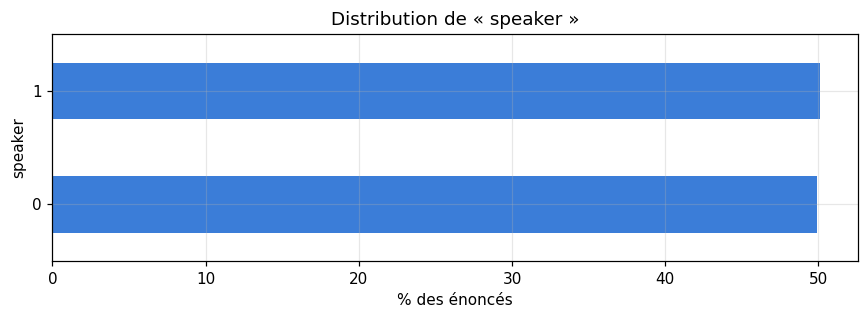

Déséquilibre speaker: max/min = 1.0


In [7]:
cat_cols = [c for c in ["speaker", "emotion", "act", "topic"] if c in df.columns]
for c in cat_cols:
    vc = df[c].value_counts(dropna=False)
    print(f"\n=== {c} ({vc.size} modalités) ===")
    print(vc.head(20))
    fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * min(vc.size, 25))))
    (vc.head(25)[::-1] / len(df) * 100).plot.barh(ax=ax, color="#3b7dd8")
    ax.set_xlabel("% des énoncés"); ax.set_title(f"Distribution de « {c} »")
    savefig(f"cat_{c}")
    report.setdefault("class_counts", {})[c] = {str(k): int(v) for k, v in vc.items()}

# Déséquilibre (ratio majoritaire / minoritaire)
for c in cat_cols:
    vc = df[c].value_counts()
    print(f"Déséquilibre {c}: max/min = {vc.max() / vc.min():.1f}")

# Croisement emotion x act (heatmap normalisée par ligne)
if {"emotion", "act"} <= set(df.columns):
    ct = pd.crosstab(df["emotion"], df["act"], normalize="index")
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(ct.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=45, ha="right")
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    ax.grid(False); plt.colorbar(im, label="P(act | emotion)"); ax.set_title("Émotion × Dialog act")
    savefig("emotion_x_act")

## 3.3 EDA texte

                 count       mean        std       min        1%         5%  \
n_chars        23773.0  43.748664  25.848487  3.000000  4.720000  11.000000   
n_words        23773.0   8.630884   5.031518  1.000000  1.000000   2.000000   
duration       23773.0   3.282163   1.730983  0.505667  0.876863   1.188117   
words_per_sec  23773.0   2.601616   0.699308  0.247198  0.861886   1.371178   

                    50%        95%         99%         max  
n_chars        38.00000  93.000000  123.000000  258.000000  
n_words         8.00000  18.000000   24.000000   48.000000  
duration        2.91050   6.611167    8.657055   17.836708  
words_per_sec   2.62115   3.711407    4.225934    7.361461  


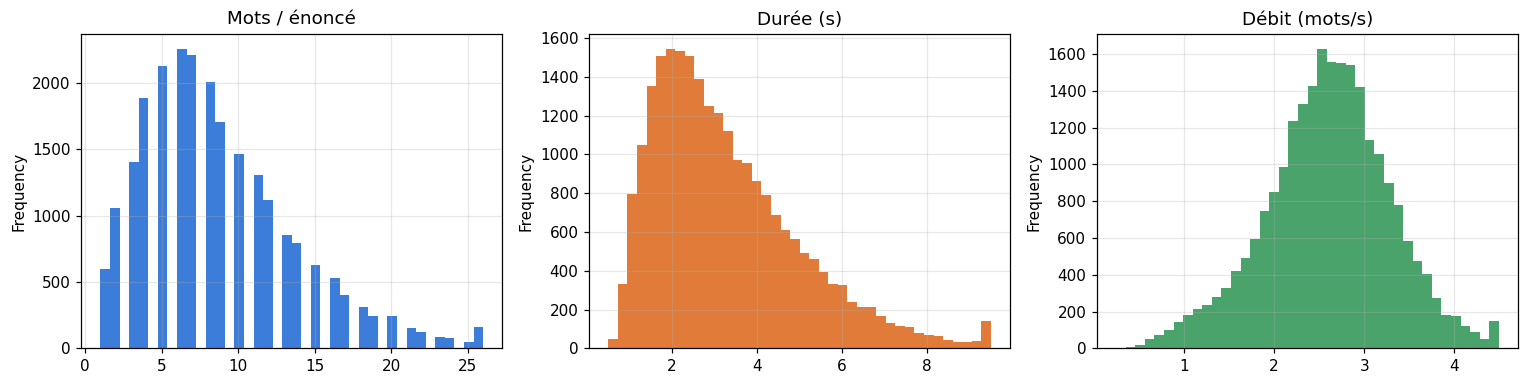

Corrélation durée / nb mots : 0.909  (attendu > 0.8 si audio et texte alignés)


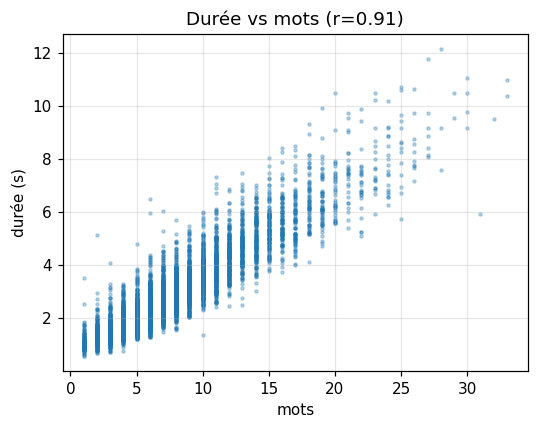


Vocabulaire : 8197 mots uniques, 207530 tokens
Top 30 mots : [('you', 9124), ('i', 7707), ('the', 6172), ('to', 5211), ('a', 4966), ('it', 3845), ('is', 3169), ('have', 2421), ('do', 2399), ('and', 2381), ('for', 2181), ('of', 2034), ('in', 2007), ('that', 1913), ('are', 1874), ('what', 1864), ('can', 1685), ('like', 1658), ('your', 1653), ('me', 1644), ('yes', 1609), ('this', 1532), ('my', 1426), ('how', 1379), ('umm', 1294), ('we', 1273), ("it's", 1252), ('on', 1213), ('be', 1178), ('but', 1145)]
Hapax : 3366 (41.1% du vocabulaire)


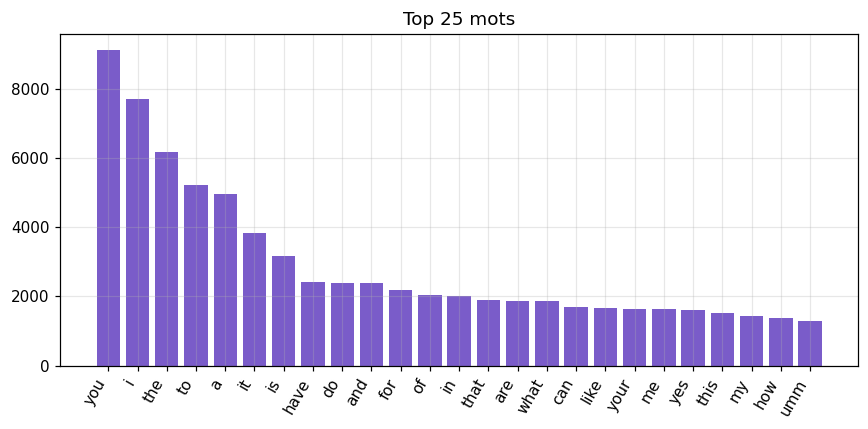

Caractères non standards : {'’': 1450, '…': 86, '(': 51, ')': 51, ':': 47, ';': 28, '"': 19, '—': 10, '‘': 5, '&': 5, '“': 4, '”': 4, '–': 3, '/': 2, '。': 1, '\\': 1}
Textes avec espaces multiples / bords : 12
Textes vides : 0


In [8]:
df["text"] = df["text"].fillna("").astype(str)
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()
df["words_per_sec"] = df["n_words"] / df["duration"]

print(df[["n_chars", "n_words", "duration", "words_per_sec"]].describe(percentiles=[.01, .05, .5, .95, .99]).T)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
df["n_words"].clip(upper=df["n_words"].quantile(.995)).plot.hist(bins=40, ax=axes[0], color="#3b7dd8")
axes[0].set_title("Mots / énoncé")
df["duration"].clip(upper=df["duration"].quantile(.995)).plot.hist(bins=40, ax=axes[1], color="#e07b39")
axes[1].set_title("Durée (s)")
df["words_per_sec"].clip(upper=df["words_per_sec"].quantile(.995)).plot.hist(bins=40, ax=axes[2], color="#4aa36b")
axes[2].set_title("Débit (mots/s)")
savefig("text_audio_lengths")

# Corrélation durée ~ nb de mots (sanity check de l'alignement texte/audio)
corr = df[["duration", "n_words"]].corr().iloc[0, 1]
print(f"Corrélation durée / nb mots : {corr:.3f}  (attendu > 0.8 si audio et texte alignés)")
fig, ax = plt.subplots(figsize=(5, 4))
s = df.sample(min(5000, len(df)), random_state=SEED)
ax.scatter(s["n_words"], s["duration"], s=4, alpha=.3); ax.set_xlabel("mots"); ax.set_ylabel("durée (s)")
ax.set_title(f"Durée vs mots (r={corr:.2f})")
savefig("duration_vs_words")

# Vocabulaire, mots fréquents, caractères inhabituels
tok = lambda t: re.findall(r"[a-zA-Z']+", t.lower())
counter = Counter(w for t in df["text"] for w in tok(t))
print(f"\nVocabulaire : {len(counter)} mots uniques, {sum(counter.values())} tokens")
print("Top 30 mots :", counter.most_common(30))
hapax = sum(1 for c in counter.values() if c == 1)
print(f"Hapax : {hapax} ({hapax / len(counter):.1%} du vocabulaire)")

fig, ax = plt.subplots(figsize=(8, 4))
top = counter.most_common(25)
ax.bar([w for w, _ in top], [c for _, c in top], color="#7a5cc9"); plt.xticks(rotation=60, ha="right")
ax.set_title("Top 25 mots")
savefig("top_words")

char_counter = Counter(ch for t in df["text"] for ch in t)
odd = {c: n for c, n in char_counter.items() if not (c.isascii() and (c.isalnum() or c in " .,!?'-"))}
print("Caractères non standards :", dict(sorted(odd.items(), key=lambda x: -x[1])[:30]))
print("Textes avec espaces multiples / bords :",
      int(df["text"].str.contains(r"\s{2,}|^\s|\s$").sum()))
print("Textes vides :", int((df["n_words"] == 0).sum()))

## 3.4 EDA audio


Sample rates : {24000: 23773}
Canaux : {1: 23773}
Durée totale : 21.67 h
Énoncés avec clipping > 0.1% : 12


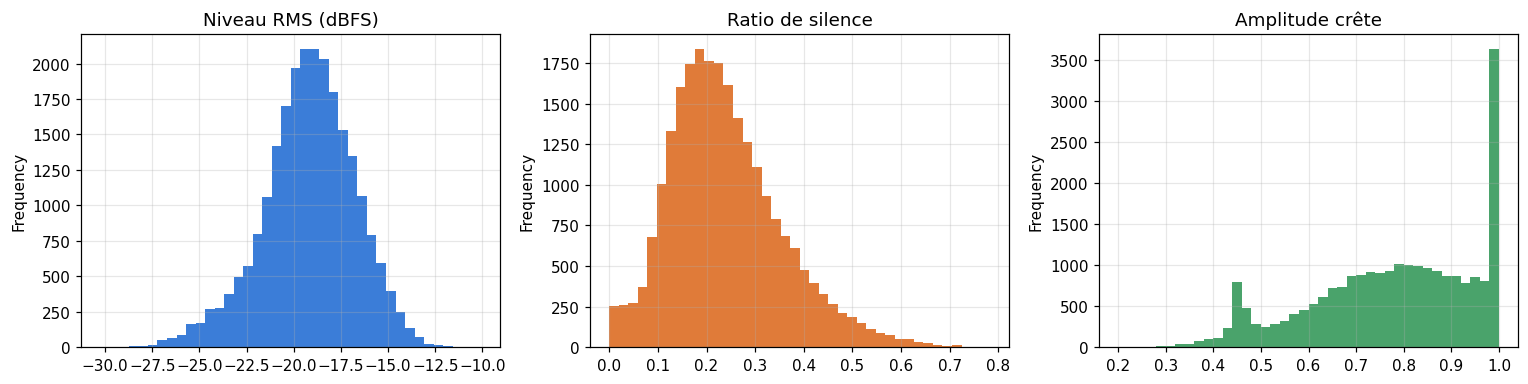

C:\Users\rania\AppData\Local\Temp\ipykernel_14736\2931557128.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df.loc[df[c] == k, "duration"].clip(upper=20) for k in order],


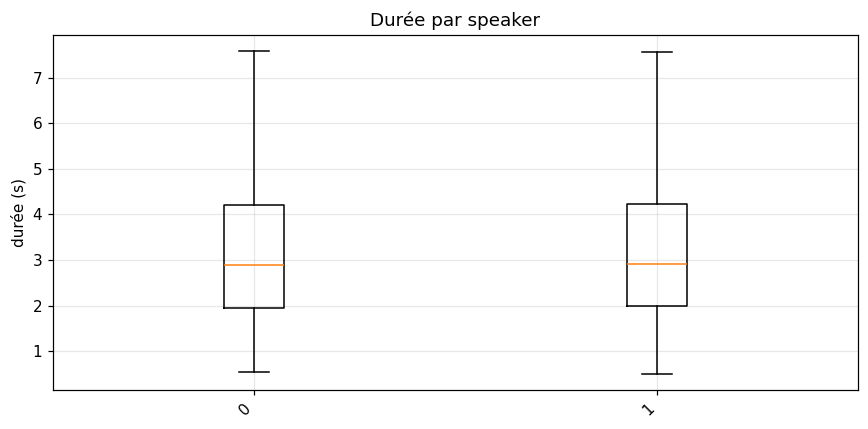

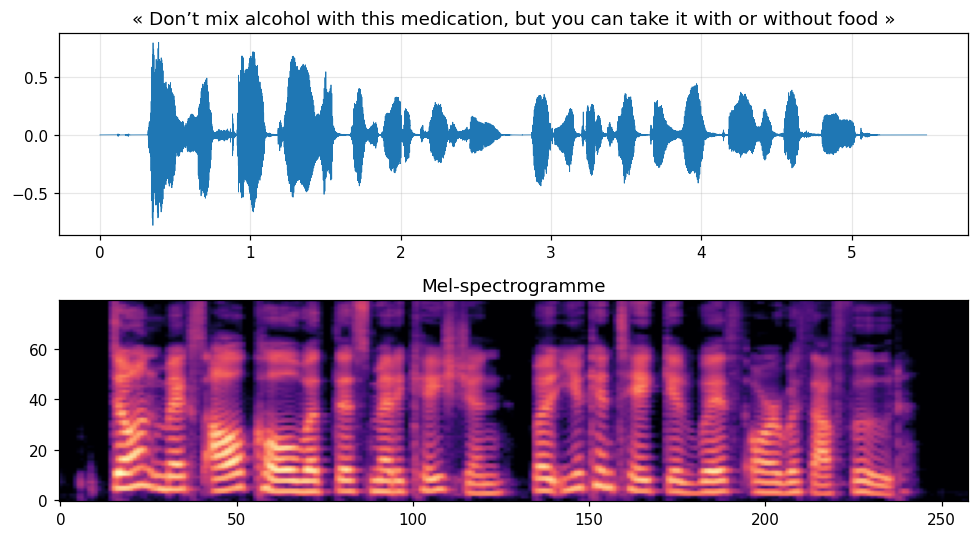

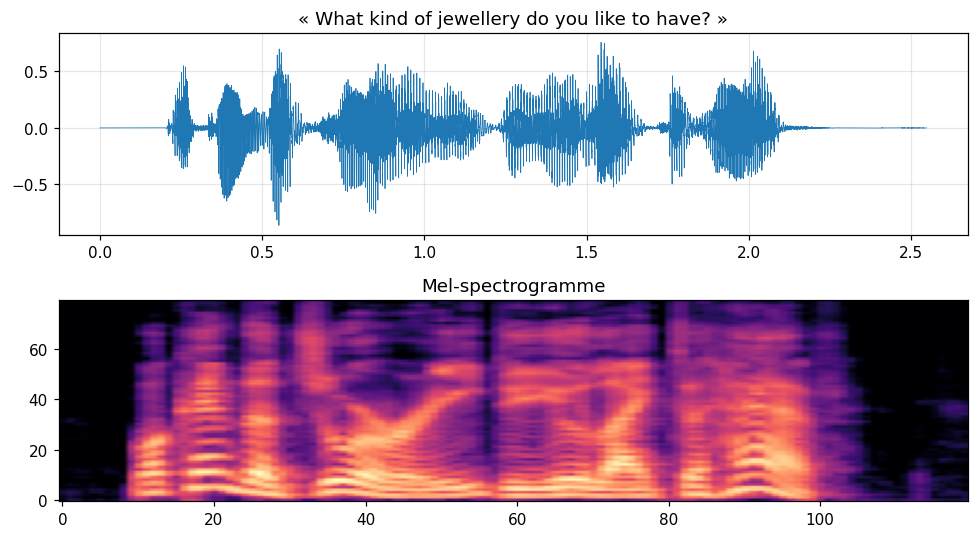

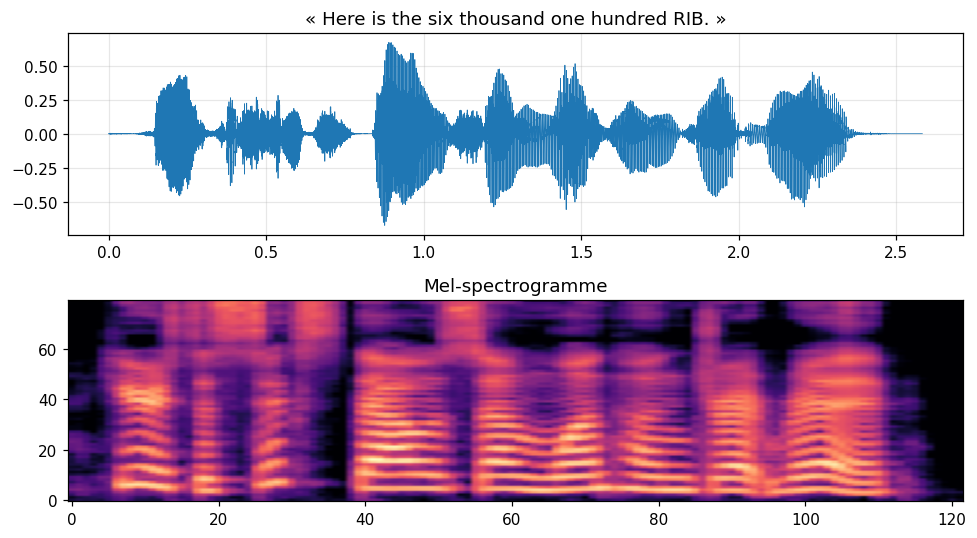

In [9]:
print("\nSample rates :", df["sr"].value_counts().to_dict())
print("Canaux :", df["channels"].value_counts().to_dict())
print(f"Durée totale : {df['duration'].sum() / 3600:.2f} h")
print("Énoncés avec clipping > 0.1% :", int((df["clipping_ratio"] > 1e-3).sum()))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
df["rms_db"].plot.hist(bins=40, ax=axes[0], color="#3b7dd8"); axes[0].set_title("Niveau RMS (dBFS)")
df["silence_ratio"].plot.hist(bins=40, ax=axes[1], color="#e07b39"); axes[1].set_title("Ratio de silence")
df["peak"].plot.hist(bins=40, ax=axes[2], color="#4aa36b"); axes[2].set_title("Amplitude crête")
savefig("audio_quality")

# Durée par émotion / act / speaker (boxplots)
for c in [c for c in ["emotion", "act", "speaker"] if c in df.columns]:
    order = df.groupby(c)["duration"].median().sort_values().index
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot([df.loc[df[c] == k, "duration"].clip(upper=20) for k in order],
               labels=[str(k) for k in order], showfliers=False)
    plt.xticks(rotation=45, ha="right"); ax.set_ylabel("durée (s)"); ax.set_title(f"Durée par {c}")
    savefig(f"duration_by_{c}")

# Waveform + mel-spectrogramme de quelques exemples
for k, i in enumerate(df.sample(3, random_state=SEED).index):
    y, sr = read_audio_from_dict(ds_raw[int(i)][COL["audio"]])
    y = y.mean(axis=1)
    fig, axes = plt.subplots(2, 1, figsize=(9, 5))
    axes[0].plot(np.arange(len(y)) / sr, y, lw=.5); axes[0].set_title(f"« {df.loc[i, 'text'][:80]} »")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=80), ref=np.max)
    axes[1].imshow(S, origin="lower", aspect="auto", cmap="magma"); axes[1].grid(False)
    axes[1].set_title("Mel-spectrogramme")
    savefig(f"example_{k}")

## 3.5 EDA structure des dialogues

             count       mean        std       min        25%        50%  \
n_turns     2541.0   9.355765   3.738730  5.000000   6.000000   8.000000   
dur_total   2541.0  30.707143  15.826732  5.671167  19.619083  26.750417   
n_speakers  2541.0   2.000000   0.000000  2.000000   2.000000   2.000000   

                  75%        max  
n_turns     12.000000   20.00000  
dur_total   37.081125  103.47375  
n_speakers   2.000000    2.00000  


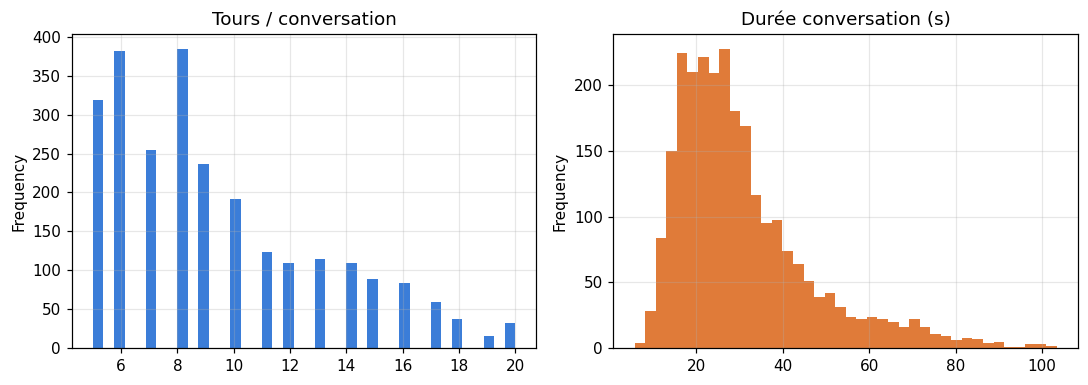

Trous dans la numérotation des tours : 0
Part de tours consécutifs du même speaker : 0.0%


In [10]:
if "conv" in df.columns:
    g = df.groupby("conv")
    conv = pd.DataFrame({"n_turns": g.size(), "dur_total": g["duration"].sum(),
                         "n_speakers": g["speaker"].nunique() if "speaker" in df else np.nan})
    print(conv.describe().T)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    conv["n_turns"].plot.hist(bins=40, ax=axes[0], color="#3b7dd8"); axes[0].set_title("Tours / conversation")
    conv["dur_total"].plot.hist(bins=40, ax=axes[1], color="#e07b39"); axes[1].set_title("Durée conversation (s)")
    savefig("conversation_stats")
    report["conversations"] = {"n": int(len(conv)), "turns_mean": float(conv["n_turns"].mean())}

    # Vérification de la continuité des tours
    if "turn" in df.columns:
        gaps = g["turn"].apply(lambda s: (np.diff(np.sort(s.values)) != 1).sum()).sum()
        print("Trous dans la numérotation des tours :", int(gaps))
        # Alternance de speakers
        if "speaker" in df.columns:
            d = df.sort_values(["conv", "turn"])
            same = (d.groupby("conv")["speaker"].shift() == d["speaker"]).mean()
            print(f"Part de tours consécutifs du même speaker : {same:.1%}")

    # Transitions d'émotion (tour t -> t+1)
    if "emotion" in df.columns and "turn" in df.columns:
        d = df.sort_values(["conv", "turn"]).copy()
        d["next_emotion"] = d.groupby("conv")["emotion"].shift(-1)
        tr = pd.crosstab(d["emotion"], d["next_emotion"], normalize="index")
        fig, ax = plt.subplots(figsize=(6, 5))
        im = ax.imshow(tr.values, cmap="Blues"); ax.grid(False)
        ax.set_xticks(range(tr.shape[1])); ax.set_xticklabels(tr.columns, rotation=45, ha="right")
        ax.set_yticks(range(tr.shape[0])); ax.set_yticklabels(tr.index)
        plt.colorbar(im); ax.set_title("Transitions d'émotion (t → t+1)")
        savefig("emotion_transitions")

## 4. PREPROCESSING — texte

In [11]:
def clean_text(t: str) -> str:
    """Nettoyage léger : conserve la casse et la ponctuation (utile pour TTS / modèles de dialogue)."""
    t = unicodedata.normalize("NFKC", t)
    t = (t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
          .replace("…", "...").replace("–", "-").replace("—", "-"))
    t = re.sub(r"\s+", " ", t).strip()
    return t


def normalize_text(t: str) -> str:
    """Version normalisée (minuscule, sans ponctuation) : utile pour ASR / calcul de WER."""
    t = clean_text(t).lower()
    t = re.sub(r"[^a-z0-9' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


df["text_clean"] = df["text"].map(clean_text)
df["text_norm"] = df["text"].map(normalize_text)
df["n_words"] = df["text_clean"].str.split().str.len()
df["words_per_sec"] = df["n_words"] / df["duration"]

## 4.1 Filtrage des outliers (avec traçabilité de chaque règle)

In [12]:
n0 = len(df)
rules = {}
mask = pd.Series(True, index=df.index)


def apply_rule(name, cond):
    """cond = True pour les lignes À GARDER."""
    global mask
    rules[name] = int((mask & ~cond).sum())
    mask &= cond


apply_rule("audio_illisible", df["duration"].notna())
apply_rule("texte_vide", df["text_norm"].str.len() > 0)
apply_rule("duree_hors_bornes", df["duration"].between(MIN_DUR, MAX_DUR))

# Débit anormal : bornes IQR étendues (alignement texte/audio douteux)
q1, q3 = df.loc[mask, "words_per_sec"].quantile([.25, .75])
iqr = q3 - q1
lo, hi = max(0.3, q1 - 3 * iqr), q3 + 3 * iqr
print(f"Bornes de débit retenues : [{lo:.2f}, {hi:.2f}] mots/s")
apply_rule("debit_aberrant", df["words_per_sec"].between(lo, hi))
apply_rule("clipping_excessif", df["clipping_ratio"] < 0.01)
apply_rule("quasi_silence", df["silence_ratio"] < 0.95)

df_f = df[mask].copy()
print(f"\nFiltrage : {n0} -> {len(df_f)} ({len(df_f) / n0:.1%} gardés)")
print("Lignes retirées par règle :", rules)
report["filtering"] = {"before": n0, "after": int(len(df_f)), "removed_by_rule": rules,
                       "wps_bounds": [float(lo), float(hi)]}

# Dédoublonnage : on ne supprime PAS les textes courts répétés (« Yes. », « Okay. » sont légitimes
# dans un dialogue) ; on supprime seulement les doublons exacts (même conv, même tour).
if {"conv", "turn"} <= set(df_f.columns):
    before = len(df_f)
    df_f = df_f.drop_duplicates(subset=["conv", "turn"])
    print("Doublons (conv, turn) supprimés :", before - len(df_f))

Bornes de débit retenues : [0.30, 5.65] mots/s

Filtrage : 23773 -> 23762 (100.0% gardés)
Lignes retirées par règle : {'audio_illisible': 0, 'texte_vide': 0, 'duree_hors_bornes': 0, 'debit_aberrant': 11, 'clipping_excessif': 0, 'quasi_silence': 0}
Doublons (conv, turn) supprimés : 0


## 5. PREPROCESSING — audio (mono, 16 kHz, trim, normalisation) + écriture wav

In [13]:
def process_audio(y_multi, sr):
    y = y_multi.mean(axis=1)                                     # mono
    if sr != TARGET_SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)  # 16 kHz
    y, _ = librosa.effects.trim(y, top_db=TRIM_TOP_DB)           # retire silences début/fin
    y = y - np.mean(y)                                           # retire l'offset DC
    peak = np.max(np.abs(y)) + 1e-9
    return (y / peak * PEAK_TARGET).astype(np.float32)           # normalisation de crête


if SAVE_AUDIO:
    paths, new_dur = {}, {}
    for i in tqdm(df_f["idx"].tolist(), desc="Traitement audio"):
        y, sr = read_audio_from_dict(ds_raw[int(i)][COL["audio"]])
        y = process_audio(y, sr)
        if len(y) < MIN_DUR * TARGET_SR:  # trop court après trim
            continue
        p = AUDIO_DIR / f"utt_{int(i):06d}.wav"
        sf.write(p, y, TARGET_SR, subtype="PCM_16")
        paths[i], new_dur[i] = str(p.resolve()), len(y) / TARGET_SR
    df_f["audio_path"] = df_f["idx"].map(paths)
    df_f["duration_16k"] = df_f["idx"].map(new_dur)
    df_f = df_f.dropna(subset=["audio_path"])
    print(f"Durée avant trim : {df_f['duration'].sum() / 3600:.2f} h | "
          f"après : {df_f['duration_16k'].sum() / 3600:.2f} h")

Traitement audio: 100%|██████████| 23762/23762 [06:09<00:00, 64.29it/s]


Durée avant trim : 21.67 h | après : 18.61 h


## 6. Features de dialogue, encodage des labels, poids de classes

In [14]:
if {"conv", "turn"} <= set(df_f.columns):
    df_f = df_f.sort_values(["conv", "turn"]).reset_index(drop=True)
    g = df_f.groupby("conv")
    df_f["prev_text"] = g["text_clean"].shift(1).fillna("")
    for k in range(1, CONTEXT_TURNS + 1):
        df_f[f"_p{k}"] = g["text_clean"].shift(k).fillna("")
    df_f["context"] = df_f[[f"_p{k}" for k in range(CONTEXT_TURNS, 0, -1)]].apply(
        lambda r: " [SEP] ".join(x for x in r if x), axis=1)
    df_f["is_first_turn"] = (g.cumcount() == 0).astype(int)
    df_f["turn_position"] = g.cumcount() / g["text_clean"].transform("size")
    df_f = df_f.drop(columns=[f"_p{k}" for k in range(1, CONTEXT_TURNS + 1)])

label_maps, class_weights = {}, {}
for c in [c for c in ["emotion", "act", "topic"] if c in df_f.columns]:
    classes = sorted(df_f[c].dropna().astype(str).unique())
    label_maps[c] = {k: i for i, k in enumerate(classes)}
    df_f[f"{c}_id"] = df_f[c].astype(str).map(label_maps[c])
    w = compute_class_weight("balanced", classes=np.arange(len(classes)), y=df_f[f"{c}_id"])
    class_weights[c] = {classes[i]: float(w[i]) for i in range(len(classes))}
print("Label maps :", label_maps)
print("Poids de classes (loss pondérée) :", json.dumps(class_weights, indent=1))
report["label_maps"], report["class_weights"] = label_maps, class_weights

Label maps : {}
Poids de classes (loss pondérée) : {}


## 7. Split train / val / test PAR CONVERSATION (80 / 10 / 10)

In [15]:
if "conv" in df_f.columns:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    tr_idx, tmp_idx = next(gss.split(df_f, groups=df_f["conv"]))
    tmp = df_f.iloc[tmp_idx]
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
    va_rel, te_rel = next(gss2.split(tmp, groups=tmp["conv"]))
    df_f["split"] = "train"
    df_f.loc[tmp.index[va_rel], "split"] = "validation"
    df_f.loc[tmp.index[te_rel], "split"] = "test"
else:
    rng = np.random.default_rng(SEED)
    df_f["split"] = rng.choice(["train", "validation", "test"], size=len(df_f), p=[.8, .1, .1])

print(df_f["split"].value_counts())
# Vérification anti-fuite : aucune conversation dans 2 splits
if "conv" in df_f.columns:
    leak = df_f.groupby("conv")["split"].nunique().gt(1).sum()
    print("Conversations présentes dans plusieurs splits :", int(leak), "(doit être 0)")
    assert leak == 0

# Vérification que la distribution des classes est préservée
for c in [c for c in ["emotion", "act"] if c in df_f.columns]:
    print(f"\n{c} par split (%):")
    print((pd.crosstab(df_f[c], df_f["split"], normalize="columns") * 100).round(1))

split
train         18961
test           2441
validation     2360
Name: count, dtype: int64
Conversations présentes dans plusieurs splits : 0 (doit être 0)


## 8. Sauvegarde des résultats

Les sorties sont enregistrées automatiquement dans `SpeechToText/data/` :

- `data/raw/` : métadonnées et statistiques audio initiales au format CSV.
- `data/processed/` : dataset nettoyé et splits train/validation/test au format CSV, audios WAV 16 kHz, figures et rapport JSON.

Les colonnes complexes (listes/dictionnaires, par exemple `audio_codes`) sont sérialisées en JSON dans les fichiers CSV. Le notebook détecte automatiquement le dossier racine `SpeechToText`.


In [16]:
# Sauvegarde des données préparées au format CSV dans data/processed/
drop_cols = [c for c in ["error", "idx"] if c in df_f.columns]
df_final = df_f.drop(columns=drop_cols).copy()

# Dataset complet nettoyé + jeux train/validation/test
save_csv(df_final, PROCESSED_DIR / "dailytalk_clean.csv", index=False)
for s in ["train", "validation", "test"]:
    save_csv(
        df_final[df_final["split"] == s],
        PROCESSED_DIR / f"{s}.csv",
        index=False
    )

report["final"] = {
    "n_utterances": int(len(df_final)),
    "hours_16k": float(df_final.get("duration_16k", df_final["duration"]).sum() / 3600),
    "splits": {k: int(v) for k, v in df_final["split"].value_counts().items()}
}
report["paths"] = {
    "raw_dir": str(RAW_DIR),
    "processed_dir": str(PROCESSED_DIR),
    "audio_dir": str(AUDIO_DIR),
    "figures_dir": str(FIG_DIR)
}
with open(PROCESSED_DIR / "report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False, default=str)

print("\n✅ Terminé. Résultats enregistrés dans :", DATA_DIR)
print("data/raw/")
print(" - dailytalk_metadata_audio_stats.csv")
print(" - dailytalk_audio_stats.csv")
print("data/processed/")
print(" - dailytalk_clean.csv")
print(" - train.csv, validation.csv, test.csv")
print(" - audio_16k/*.wav")
print(" - figures/*.png")
print(" - report.json")



✅ Terminé. Résultats enregistrés dans : C:\Users\rania\Downloads\ml\SpeechToText\data
data/raw/
 - dailytalk_metadata_audio_stats.csv
 - dailytalk_audio_stats.csv
data/processed/
 - dailytalk_clean.csv
 - train.csv, validation.csv, test.csv
 - audio_16k/*.wav
 - figures/*.png
 - report.json


## Recharger le dataset nettoyé (audio décodé à la volée)

In [17]:
from datasets import load_dataset, Audio

# Rechargement des splits CSV préparés depuis data/processed/
ds = load_dataset(
    "csv",
    data_files={
        "train": str(PROCESSED_DIR / "train.csv"),
        "validation": str(PROCESSED_DIR / "validation.csv"),
        "test": str(PROCESSED_DIR / "test.csv"),
    }
)

# Les colonnes contenant des structures imbriquées (ex. audio_codes)
# sont stockées comme chaînes JSON dans le CSV.
# La colonne audio_path pointe vers les fichiers WAV prétraités.
ds = ds.rename_column("audio_path", "audio").cast_column(
    "audio", Audio(sampling_rate=TARGET_SR)
)
print(ds)


Generating train split: 18961 examples [00:07, 2505.09 examples/s]
Generating validation split: 2360 examples [00:00, 2915.55 examples/s]
Generating test split: 2441 examples [00:00, 2665.10 examples/s]


DatasetDict({
    train: Dataset({
        features: ['conv', 'turn', 'speaker', 'text', 'audio_codes', 'sr', 'channels', 'duration', 'rms_db', 'peak', 'clipping_ratio', 'silence_ratio', 'n_chars', 'n_words', 'words_per_sec', 'text_clean', 'text_norm', 'audio', 'duration_16k', 'prev_text', 'context', 'is_first_turn', 'turn_position', 'split'],
        num_rows: 18961
    })
    validation: Dataset({
        features: ['conv', 'turn', 'speaker', 'text', 'audio_codes', 'sr', 'channels', 'duration', 'rms_db', 'peak', 'clipping_ratio', 'silence_ratio', 'n_chars', 'n_words', 'words_per_sec', 'text_clean', 'text_norm', 'audio', 'duration_16k', 'prev_text', 'context', 'is_first_turn', 'turn_position', 'split'],
        num_rows: 2360
    })
    test: Dataset({
        features: ['conv', 'turn', 'speaker', 'text', 'audio_codes', 'sr', 'channels', 'duration', 'rms_db', 'peak', 'clipping_ratio', 'silence_ratio', 'n_chars', 'n_words', 'words_per_sec', 'text_clean', 'text_norm', 'audio', 'duration